# Самостоятельная работа: языковая модель на Elman RNN

В этом ноутбуке требуется самостоятельно собрать словарную языковую
модель следующего слова. Учебный маршрут совпадает с подробным
примером, но все содержательные части реализации заполнены
в кодовых ячейках. Здесь используется отдельный
корпус русской классической литературы RuHeritage-Corpus, поэтому
данные, жанр и словарь не совпадают с примером.

## Маршрут самостоятельной работы

Выполняйте ячейки по порядку. В каждой спецификации указаны доступные
переменные, входы, ожидаемые формы и контрольная точка. Не вставляйте
готовое решение из примера: воспроизведите необходимые преобразования
самостоятельно. Индексы токенов являются входом модели, а целевые
индексы следующего токена — вторым аргументом функции потерь. Меток
классов документа в этой работе нет. Каждый этап имеет одну и ту же
структуру: цель, входы, действия, ожидаемый результат и контрольная
точка. Если проверка не пройдена, не переходите к следующему этапу.

**Выполненное решение.** Реализованы все этапы, включая контрольные проверки и сохранение лучшей модели. Исходный шаблон оставлен без изменений. Среда: CPU, Python 3.12 вместо рекомендованного 3.13, PyTorch 2.13.0. Гиперпараметры и объём выборки сохранены. Для разбиения считаем пригодными документы минимум из двух русских токенов; каждый шестой такой документ (6, 12, …) уходит в валидацию. Просматриваем ровно первые 1 200 записей, как указано в самостоятельном ноутбуке, и явно выводим число исключённых записей. Исходный корпус не записывается в папку работы.


## Этап 1. Настройка самостоятельного эксперимента

**Цель:** зафиксировать независимую от примера постановку. Константы
выбирают RuHeritage-Corpus, его каталог данных «data», закреплённую
ревизию и поле «text». Первые 1 200 документов этого *другого*
потока достаточны для учебного CPU-эксперимента.

**Результат этапа:** определены все размеры модели и специальные
индексы. **Проверьте:** PAD, UNK, BOS и EOS равны соответственно
0, 1, 2 и 3; «MAX_SEQUENCE_LENGTH» равна 32. Эти числа — часть
контракта следующих этапов: индекс 0 будет маскироваться в потере, а
размерности 128 и два рекуррентных слоя определяют формы параметров.

In [1]:
from __future__ import annotations

import copy
import math
import random
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from datasets import load_dataset
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

SEED = 42
DATASET_NAME = 'maxzt/RuHeritage-Corpus'
DATASET_REVISION = 'b2d01eaad3ddb119fe10c4cb17a86e47415a77cb'
DATASET_DATA_DIR = 'data'
TEXT_FIELD = 'text'
START_DOCUMENT = 0
MAX_DOCUMENTS = 1_200
MAX_WORDS_PER_DOCUMENT = 160
MAX_ORDINARY_WORDS = 6_000
MAX_SEQUENCE_LENGTH = 32
EMBEDDING_DIM = 128
HIDDEN_DIM = 128
NUM_LAYERS = 2
BATCH_SIZE = 64
LEARNING_RATE = 2e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 12
PATIENCE = 3

SPECIAL_TOKENS = ['<pad>', '<unk>', '<bos>', '<eos>']
PAD_IDX, UNK_IDX, BOS_IDX, EOS_IDX = range(4)
DEVICE = torch.device('cpu')

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
import json, hashlib, sys, time, platform
from itertools import islice
import datasets

torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
ARTIFACT_DIR = Path('artifacts/assignment')
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
experiment_start = time.perf_counter()
config = {name: globals()[name] for name in [
    'SEED','DATASET_NAME','DATASET_REVISION','DATASET_DATA_DIR','TEXT_FIELD',
    'START_DOCUMENT','MAX_DOCUMENTS','MAX_WORDS_PER_DOCUMENT','MAX_ORDINARY_WORDS',
    'MAX_SEQUENCE_LENGTH','EMBEDDING_DIM','HIDDEN_DIM','NUM_LAYERS','BATCH_SIZE',
    'LEARNING_RATE','WEIGHT_DECAY','MAX_EPOCHS','PATIENCE']}
config.update(python=sys.version.split()[0], torch=torch.__version__, datasets=datasets.__version__,
              numpy=np.__version__, device=str(DEVICE), threads=torch.get_num_threads())
(ARTIFACT_DIR/'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2))
assert (PAD_IDX,UNK_IDX,BOS_IDX,EOS_IDX)==(0,1,2,3)
assert MAX_SEQUENCE_LENGTH==32 and NUM_LAYERS==2
print(json.dumps(config,ensure_ascii=False,indent=2))


/private/tmp/linear-algebra-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
  "SEED": 42,
  "DATASET_NAME": "maxzt/RuHeritage-Corpus",
  "DATASET_REVISION": "b2d01eaad3ddb119fe10c4cb17a86e47415a77cb",
  "DATASET_DATA_DIR": "data",
  "TEXT_FIELD": "text",
  "START_DOCUMENT": 0,
  "MAX_DOCUMENTS": 1200,
  "MAX_WORDS_PER_DOCUMENT": 160,
  "MAX_ORDINARY_WORDS": 6000,
  "MAX_SEQUENCE_LENGTH": 32,
  "EMBEDDING_DIM": 128,
  "HIDDEN_DIM": 128,
  "NUM_LAYERS": 2,
  "BATCH_SIZE": 64,
  "LEARNING_RATE": 0.002,
  "WEIGHT_DECAY": 0.0001,
  "MAX_EPOCHS": 12,
  "PATIENCE": 3,
  "python": "3.12.14",
  "torch": "2.13.0",
  "datasets": "5.2.0",
  "numpy": "2.5.5",
  "device": "cpu",
  "threads": 4
}


## Этап 2. Получение литературных документов и нормализация

**Цель:** превратить поток записей литературного корпуса в два списка
коротких последовательностей слов. **Входы:** «DATASET_NAME»,
«DATASET_REVISION», «DATASET_DATA_DIR», «TEXT_FIELD» и строка поля
«text». При загрузке передайте каталог данных «data», закреплённую
ревизию, «split='train'» и потоковый режим.

**Действие:** прочитайте только первые 1 200 документов, нормализуйте
текст, выделите русские словарные токены и оставьте не более 160 слов
на документ. Каждый шестой непустой документ направьте в валидацию.

Направляйте каждый шестой непустой документ в валидацию, остальные —
в обучение. Результат должен состоять из двух непустых списков
документов, где каждый документ является списком строк. Выведите
размеры и пример токенов. **Математический смысл:** в этот момент
строки превращаются в последовательности дискретных символов, но
ещё не в числа и не в векторы. **Контрольная точка:** не скачивается
весь корпус; обе части непусты; используется поле «text» именно
RuHeritage-Corpus. Если документ после нормализации слишком короток
для пары «вход — следующий токен», его разумно исключить до разбиения
на окна.

**Реализовано и проверено.** После нормализации исключаются строки короче двух токенов. Разбиение происходит на уровне документов до подсчёта частот; хэш выборки фиксирует именно выбранные нормализованные префиксы. Отдельно проверяется совпадение префиксов между частями: документное разбиение не гарантирует независимости авторов и произведений.


In [2]:
WORD_RE = re.compile(r'[а-яё]+(?:-[а-яё]+)?', re.IGNORECASE)

def normalize_and_tokenize(text, max_words=MAX_WORDS_PER_DOCUMENT):
    if text is None:
        return []
    return WORD_RE.findall(' '.join(str(text).lower().split()))[:max_words]

stream = load_dataset(DATASET_NAME, data_dir=DATASET_DATA_DIR,
                      revision=DATASET_REVISION, split='train', streaming=True)
train_documents, val_documents = [], []
train_document_indices, val_document_indices = [], []
seen = accepted = skipped = 0
fingerprint = hashlib.sha256()
for raw_index, row in enumerate(islice(stream, START_DOCUMENT, START_DOCUMENT+MAX_DOCUMENTS), START_DOCUMENT):
    seen += 1
    tokens = normalize_and_tokenize(row.get(TEXT_FIELD,''))
    fingerprint.update(json.dumps([raw_index,tokens],ensure_ascii=False).encode('utf-8'))
    if len(tokens)<2:
        skipped += 1
        continue
    accepted += 1
    if accepted % 6 == 0:
        val_documents.append(tokens);val_document_indices.append(raw_index)
    else:
        train_documents.append(tokens);train_document_indices.append(raw_index)
assert seen==MAX_DOCUMENTS and train_documents and val_documents
assert set(train_document_indices).isdisjoint(val_document_indices)
assert all(2<=len(doc)<=MAX_WORDS_PER_DOCUMENT for doc in train_documents+val_documents)
data_stats = dict(seen=seen,accepted=accepted,skipped=skipped,
                  train_documents=len(train_documents),val_documents=len(val_documents),
                  train_words=sum(map(len,train_documents)),val_words=sum(map(len,val_documents)),
                  subset_sha256=fingerprint.hexdigest())
# Хэши позволяют диагностировать одинаковые нормализованные фрагменты без хранения корпуса.
train_hashes = {hashlib.sha256(' '.join(d).encode()).hexdigest() for d in train_documents}
val_hashes = {hashlib.sha256(' '.join(d).encode()).hexdigest() for d in val_documents}
data_stats['identical_prefixes_between_splits'] = len(train_hashes & val_hashes)
print(json.dumps(data_stats,ensure_ascii=False,indent=2))
for i,document in enumerate(train_documents[:3],1): print(f'Фрагмент {i}:',document[:16])
(ARTIFACT_DIR/'data_stats.json').write_text(json.dumps(data_stats,ensure_ascii=False,indent=2))


{
  "seen": 1200,
  "accepted": 1200,
  "skipped": 0,
  "train_documents": 1000,
  "val_documents": 200,
  "train_words": 154443,
  "val_words": 31216,
  "subset_sha256": "5e19a9967e50a07821239a2ec52e3d9fc703050a9bda740f1f5c75fdce524475",
  "identical_prefixes_between_splits": 47
}
Фрагмент 1: ['михаил', 'ломоносов', 'полидор', 'идиллия', 'м', 'в', 'ломоносов', 'избранные', 'произведения', 'библиотека', 'поэта', 'большая', 'серия', 'л', 'с', 'подготовка']
Фрагмент 2: ['википроекты', 'данные', 'примечания', 'эпиграмма', 'метит', 'не', 'только', 'в', 'кн', 'шихматова', 'как', 'толкует', 'ее', 'л', 'н', 'майков']
Фрагмент 3: ['другие', 'редакции', 'в', 'дореформенной', 'орфографии', 'стихотворения', 'в', 'а', 'жуковский', 'в', 'воспоминаниях', 'современников', 'м', 'наука', 'школа', 'языки']


282

## Этап 3. Построение словаря и пар обучения

**Цель:** получить конечное индексное представление текста и
сформировать учебные примеры. **Доступные данные:** «train_documents», «val_documents»,
«SPECIAL_TOKENS», «MAX_ORDINARY_WORDS», «MAX_SEQUENCE_LENGTH».
**Требуется:** построить словарь только по обучающим документам с
резервированием индексов 0–3; незнакомые слова в обеих частях должны
переходить в «<unk>».

**Действие:** затем добавьте «<bos>» и «<eos>», разбейте длинный документ на окна не
длиннее 33 индексов и создайте пары «вход — цель» сдвигом на один
токен. Один объект Dataset должен вернуть два одномерных тензора
одинаковой длины, не превышающей 32. Контрольная точка: для пары
«[bos, a, b, eos]» вход равен «[bos, a, b]», а цель — «[a, b, eos]».
**Математический смысл:** второй массив — не метка документа, а
правильный класс следующего слова на каждой позиции. **Формы:** до
объединения в мини-пакет обе части одной пары одномерны, $(L)$, где
$1\leq L\leq32$; только функция объединения добавит ось $B$.

**Реализовано и проверено.** Каждый переход токен→следующий токен учитывается ровно один раз. Соседние окна используют общий граничный токен, но не повторяют целевые переходы. UNK остаётся настоящей целью и участвует в потере. Дополнительно измерены доли UNK в обеих частях.


In [3]:
frequencies = Counter(word for document in train_documents for word in document)
itos = SPECIAL_TOKENS + [word for word,_ in frequencies.most_common(MAX_ORDINARY_WORDS)]
stoi = {word:index for index,word in enumerate(itos)}
VOCAB_SIZE = len(itos)
assert [stoi[t] for t in SPECIAL_TOKENS]==[0,1,2,3]
assert VOCAB_SIZE<=MAX_ORDINARY_WORDS+4
assert set(itos[4:]).issubset(frequencies)
assert stoi.get('слово_которого_нет_в_словаре',UNK_IDX)==UNK_IDX

def encode_document(tokens):
    return [BOS_IDX]+[stoi.get(word,UNK_IDX) for word in tokens]+[EOS_IDX]

def pairs_from_ids(ids):
    result=[]
    for offset in range(0,len(ids)-1,MAX_SEQUENCE_LENGTH):
        window=ids[offset:offset+MAX_SEQUENCE_LENGTH+1]
        inputs=torch.tensor(window[:-1],dtype=torch.long)
        targets=torch.tensor(window[1:],dtype=torch.long)
        assert 1<=len(inputs)==len(targets)<=MAX_SEQUENCE_LENGTH
        assert torch.equal(inputs[1:],targets[:-1])
        result.append((inputs,targets))
    return result

def make_language_pairs(documents):
    return [pair for document in documents for pair in pairs_from_ids(encode_document(document))]

train_pairs=make_language_pairs(train_documents)
val_pairs=make_language_pairs(val_documents)
toy_ids=[BOS_IDX,4,5,EOS_IDX]
toy_input,toy_target=pairs_from_ids(toy_ids)[0]
assert toy_input.tolist()==[BOS_IDX,4,5] and toy_target.tolist()==[4,5,EOS_IDX]
assert sum(len(y) for _,y in train_pairs)==sum(len(d)+1 for d in train_documents)
assert sum(len(y) for _,y in val_pairs)==sum(len(d)+1 for d in val_documents)
train_unk=sum(word not in stoi for d in train_documents for word in d)
val_unk=sum(word not in stoi for d in val_documents for word in d)
data_stats.update(vocab_size=VOCAB_SIZE,train_fragments=len(train_pairs),val_fragments=len(val_pairs),
    train_targets=sum(len(y) for _,y in train_pairs),val_targets=sum(len(y) for _,y in val_pairs),
    train_unk_rate=train_unk/data_stats['train_words'],val_unk_rate=val_unk/data_stats['val_words'])
print('Словарь:',VOCAB_SIZE,'Частые слова:',frequencies.most_common(8))
print('Фрагменты train/val:',len(train_pairs),len(val_pairs))
print('UNK среди слов train/val:',data_stats['train_unk_rate'],data_stats['val_unk_rate'])
example_tokens=train_documents[0][:3]
x,y=pairs_from_ids(encode_document(example_tokens))[0]
print('Собственный пример:',example_tokens)
print('Вход:',[itos[i] for i in x.tolist()]);print('Цель:',[itos[i] for i in y.tolist()])
(ARTIFACT_DIR/'vocabulary.json').write_text(json.dumps(itos,ensure_ascii=False,indent=2))
(ARTIFACT_DIR/'data_stats.json').write_text(json.dumps(data_stats,ensure_ascii=False,indent=2))


Словарь: 6004 Частые слова: [('и', 6597), ('в', 6117), ('с', 1958), ('а', 1740), ('не', 1735), ('на', 1537), ('к', 1410), ('г', 1074)]
Фрагменты train/val: 5792 1170
UNK среди слов train/val: 0.23400218850967672 0.28767298821117376
Собственный пример: ['михаил', 'ломоносов', 'полидор']
Вход: ['<bos>', 'михаил', 'ломоносов', 'полидор']
Цель: ['михаил', 'ломоносов', 'полидор', '<eos>']


487

## Этап 4. Мини-пакет и маска технического заполнения

**Цель:** сделать пары одинаковой формы внутри одного мини-пакета.
**Вход:** список пар переменной длины. **Требуется:** написать Dataset
и функцию «collate_fn», которые вернут «input_ids» и «target_ids»
формы $(B,T)$ с $T\leq32$. Короткие строки дополните индексом
«PAD_IDX=0» справа. Создайте обучающий и валидационный DataLoader;
у обучающего допустимо перемешивание, у валидационного — нет.

**Результат:** первая полученная пара тензоров имеет одинаковую
двумерную форму, а заполнение присутствует только справа. Не путайте
«target_ids» с метками классов: это правильные следующие слова.
**Контрольная точка:** число позиций, где «target_ids» не равно
«PAD_IDX», положительно; именно эти позиции позднее войдут в среднюю
кросс-энтропию.

**Реализовано и проверено.** Проверяются правое дополнение, сдвиг, целочисленный тип и положительное число реальных целей. Диагностический пакет собирается напрямую, чтобы просмотр не менял порядок будущего перемешивания обучения.


In [4]:
class LanguageModelDataset(Dataset):
    def __init__(self,pairs):self.pairs=pairs
    def __len__(self):return len(self.pairs)
    def __getitem__(self,index):return self.pairs[index]

def collate_language_batch(batch):
    xs,ys=zip(*batch)
    return (pad_sequence(xs,batch_first=True,padding_value=PAD_IDX),
            pad_sequence(ys,batch_first=True,padding_value=PAD_IDX))

train_dataset=LanguageModelDataset(train_pairs);val_dataset=LanguageModelDataset(val_pairs)
train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True,
    generator=torch.Generator().manual_seed(SEED),collate_fn=collate_language_batch,num_workers=0)
val_loader=DataLoader(val_dataset,batch_size=BATCH_SIZE,shuffle=False,
    collate_fn=collate_language_batch,num_workers=0)
# Диагностика не потребляет генератор перемешивания обучающего DataLoader.
sample_input_ids,sample_target_ids=collate_language_batch(train_pairs[:BATCH_SIZE])
for inputs,targets in [collate_language_batch([train_pairs[0],train_pairs[-1]]),
                       (sample_input_ids,sample_target_ids)]:
    assert inputs.ndim==2 and inputs.shape==targets.shape and inputs.shape[1]<=32
    assert (targets!=PAD_IDX).sum()>0
    for a,b in zip(inputs,targets):
        length=int((b!=PAD_IDX).sum())
        assert (b[length:]==PAD_IDX).all() and (a[length:]==PAD_IDX).all()
        assert (a[:length]!=PAD_IDX).all() and torch.equal(a[1:length],b[:length-1])
# Явная проверка дополнения пары длины 2 до длины 3.
px,py=collate_language_batch([(torch.tensor([2,4]),torch.tensor([4,3])),
                            (torch.tensor([2,5,6]),torch.tensor([5,6,3]))])
assert px.tolist()==[[2,4,0],[2,5,6]] and py.tolist()==[[4,3,0],[5,6,3]]
print('input_ids / target_ids:',tuple(sample_input_ids.shape),tuple(sample_target_ids.shape))
print('Реальных целей:',int((sample_target_ids!=PAD_IDX).sum()))
print('Первые индексы входа:',sample_input_ids[0,:12].tolist())
print('Первые индексы цели:',sample_target_ids[0,:12].tolist())


input_ids / target_ids: (64, 32) (64, 32)
Реальных целей: 1732
Первые индексы входа: [2, 325, 657, 5466, 1178, 16, 5, 657, 496, 304, 256, 100]
Первые индексы цели: [325, 657, 5466, 1178, 16, 5, 657, 496, 304, 256, 100, 165]


## Этап 5. Ручная рекуррентная сеть и прогноз логитов

**Цель:** реализовать отображение индексов слов в оценки следующего
слова. **Вход модели:** «input_ids» формы $(B,T)$ со значениями от 0 до
$V-1$. **Требуемая архитектура:**
$(B,T)\rightarrow\operatorname{Embedding}(V,128)\rightarrow
\operatorname{ElmanRNN}(128,2)\rightarrow\operatorname{Linear}(128,V)$.

**Действие:** реализуйте собственный рекуррентный блок с обучаемыми входными и
рекуррентными весами, смещением и функцией tanh. Затем реализуйте два
последовательных слоя и выходную линейную проекцию. Не используйте
готовый «nn.RNN». Контрольная точка одного прямого прохода:
эмбеддинги и состояния имеют форму $(B,T,128)$, логиты — $(B,T,V)$.
Логиты ещё не являются вероятностями: это $V$ вещественных оценок,
к которым функция потерь внутренне применит softmax.

**Порядок вычислений:** индекс выбирает строку таблицы эмбеддингов;
на каждом времени рекуррентный блок объединяет этот вектор с прежним
состоянием; верхний слой получает результат нижнего; линейный слой
создаёт оценки всех слов. Результат модели обязан зависеть от
параметров класса, иначе «backward()» не сможет найти направление
их изменения.

**Реализовано и проверено.** В строковой батчевой записи переход равен $h_t=\tanh(x_tW_x^T+h_{t-1}U_h^T+b_h)$. Для каждого слоя $W_x,U_h\in\mathbb R^{128\times128}$, $b_h\in\mathbb R^{128}$. Параметры создаются один раз в конструкторе, а не внутри цикла по времени. Нулевые состояния создаются заново для каждого окна; контекст между окнами не переносится.


In [5]:
class ElmanRNNUnit(nn.Module):
    def __init__(self,input_size,hidden_size):
        super().__init__()
        self.W_x=nn.Parameter(torch.empty(hidden_size,input_size))
        self.U_h=nn.Parameter(torch.empty(hidden_size,hidden_size))
        self.b_h=nn.Parameter(torch.zeros(hidden_size))
        nn.init.xavier_uniform_(self.W_x)
        nn.init.orthogonal_(self.U_h)
    def forward(self,x_t,h_previous):
        return torch.tanh(x_t @ self.W_x.T + h_previous @ self.U_h.T + self.b_h)

class ElmanRNN(nn.Module):
    def __init__(self,hidden_size,num_layers):
        super().__init__()
        self.hidden_size=hidden_size
        self.layers=nn.ModuleList([ElmanRNNUnit(hidden_size,hidden_size) for _ in range(num_layers)])
    def forward(self,embeddings):
        states=[embeddings.new_zeros((embeddings.shape[0],self.hidden_size)) for _ in self.layers]
        time_outputs=[]
        for current_input in embeddings.unbind(dim=1):
            next_states=[]
            for cell,previous in zip(self.layers,states):
                current_input=cell(current_input,previous)
                next_states.append(current_input)
            states=next_states
            time_outputs.append(current_input)
        return torch.stack(time_outputs,dim=1)

class ElmanLanguageModel(nn.Module):
    def __init__(self,vocab_size):
        super().__init__()
        self.embedding=nn.Embedding(vocab_size,EMBEDDING_DIM,padding_idx=PAD_IDX)
        self.rnn=ElmanRNN(HIDDEN_DIM,NUM_LAYERS)
        self.output=nn.Linear(HIDDEN_DIM,vocab_size)
    def forward(self,input_ids,return_intermediates=False):
        embeddings=self.embedding(input_ids)
        hidden=self.rnn(embeddings)
        logits=self.output(hidden)
        return (logits,embeddings,hidden) if return_intermediates else logits

model=ElmanLanguageModel(VOCAB_SIZE).to(DEVICE)
with torch.no_grad():
    diagnostic_logits,diagnostic_embeddings,diagnostic_hidden=model(sample_input_ids,True)
B,T=sample_input_ids.shape
assert diagnostic_embeddings.shape==diagnostic_hidden.shape==(B,T,128)
assert diagnostic_logits.shape==(B,T,VOCAB_SIZE)
assert not any(isinstance(module,(nn.RNN,nn.GRU,nn.LSTM)) for module in model.modules())
assert torch.count_nonzero(model.embedding.weight[PAD_IDX])==0
parameter_count=sum(parameter.numel() for parameter in model.parameters())
expected_count=VOCAB_SIZE*128+2*(128*128+128*128+128)+128*VOCAB_SIZE+VOCAB_SIZE
assert parameter_count==expected_count
print('Эмбеддинги:',tuple(diagnostic_embeddings.shape))
print('Состояния:',tuple(diagnostic_hidden.shape))
print('Логиты:',tuple(diagnostic_logits.shape),'Параметров:',parameter_count)
# Веса общие по времени: сравним переход с его формулой и проверим причинность.
cell=model.rnn.layers[0]
x_check=diagnostic_embeddings[:,0];h_check=torch.ones_like(x_check)*.1
assert torch.allclose(cell(x_check,h_check),torch.tanh(F.linear(x_check,cell.W_x,cell.b_h)+F.linear(h_check,cell.U_h)))
with torch.no_grad():
    prefix_logits=model(sample_input_ids[:2,:4])
    full_logits=model(sample_input_ids[:2,:8])
assert torch.allclose(prefix_logits,full_logits[:,:4],atol=1e-6)
print('Проверки перехода и отсутствия влияния будущих токенов пройдены.')


Эмбеддинги: (64, 32, 128)
Состояния: (64, 32, 128)
Логиты: (64, 32, 6004) Параметров: 1608820
Проверки перехода и отсутствия влияния будущих токенов пройдены.


## Этап 6. Обучение по сдвинутым целям и ранняя остановка

**Цель:** изменить параметры так, чтобы правильный следующий токен
получал больший логит. **Входы каждого шага:** «input_ids» и «target_ids» формы $(B,T)$.
**Требуется:** получить логиты $(B,T,V)$, развернуть логиты и цели по
позициям, создать «CrossEntropyLoss(ignore_index=PAD_IDX)» и AdamW.
Усредняйте потерю только по незаполненным позициям; сохраняйте лучшее
состояние по валидационной потере; завершайте обучение после трёх эпох
без улучшения, но не позже 12-й.

**Порядок вычислений:** в обучающем цикле очистите градиенты, выполните прямой проход,
«backward()» и «step()». На валидации обновление параметров запрещено.
Храните списки «history['loss']» и «history['val_loss']». Контрольная
точка: все значения конечны, а потеря обучения в целом снижается.
При вычислении итоговой эпохи суммируйте отрицательные логарифмы и
число реальных токенов по всем мини-пакетам отдельно: среднее средних
при разных длинах мини-пакетов дало бы смещённую оценку.

**Реализовано и проверено.** Сумма кросс-энтропий делится на число реальных целей. Для метрики эпохи отдельно суммируются числитель и знаменатель всех пакетов. Валидация использует eval и отключённые градиенты; отсутствие изменения параметров проверено. Норма градиента ограничивается единицей для защиты от взрыва градиентов; остановка после трёх последовательных эпох без улучшения. На диск записываются веса лучшей эпохи, затем они загружаются обратно.


In [6]:
criterion=nn.CrossEntropyLoss(ignore_index=PAD_IDX,reduction='sum')
optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)

def negative_log_likelihood(logits,targets):
    count=int((targets!=PAD_IDX).sum())
    if count==0:raise ValueError('Пакет не содержит реальных целей')
    return criterion(logits.reshape(-1,logits.shape[-1]),targets.reshape(-1)),count

# Сравнение маскированной суммы с явным отбором реальных целей.
mask=sample_target_ids!=PAD_IDX
summed,count=negative_log_likelihood(diagnostic_logits,sample_target_ids)
explicit=F.cross_entropy(diagnostic_logits[mask],sample_target_ids[mask],reduction='sum')
assert torch.allclose(summed,explicit,rtol=1e-6)
# Изменение логитов на PAD-позициях не должно влиять на потерю.
test_logits=diagnostic_logits[:2,:3].clone()
test_targets=sample_target_ids[:2,:3].clone();test_targets[0,-1]=PAD_IDX
loss_before,_=negative_log_likelihood(test_logits,test_targets)
test_logits[0,-1]=torch.linspace(-100,100,VOCAB_SIZE)
loss_after,_=negative_log_likelihood(test_logits,test_targets)
assert torch.allclose(loss_before,loss_after)
# Градиенты проходят к каждому блоку; PAD-строка эмбеддинга не получает градиент.
optimizer.zero_grad(set_to_none=True)
check_logits=model(sample_input_ids[:2,:8])
check_nll,check_count=negative_log_likelihood(check_logits,sample_target_ids[:2,:8])
(check_nll/check_count).backward()
for name,parameter in model.named_parameters():
    assert parameter.grad is not None and torch.isfinite(parameter.grad).all(),name
assert torch.count_nonzero(model.embedding.weight.grad[PAD_IDX])==0
optimizer.zero_grad(set_to_none=True)
print('Проверки PAD, усреднения и обратного прохода пройдены.')

def run_epoch(loader,training=False):
    model.train(training)
    total_nll=0.;total_tokens=0
    for input_ids,target_ids in loader:
        input_ids=input_ids.to(DEVICE);target_ids=target_ids.to(DEVICE)
        if training:optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits=model(input_ids)
            nll,count=negative_log_likelihood(logits,target_ids)
            loss=nll/count
            if training:
                loss.backward()
                norm=torch.nn.utils.clip_grad_norm_(model.parameters(),max_norm=1.)
                assert torch.isfinite(norm)
                optimizer.step()
        total_nll+=nll.detach().item();total_tokens+=count
    result=total_nll/total_tokens
    assert math.isfinite(result)
    return result

initial_state={name:p.detach().clone() for name,p in model.state_dict().items()}
initial_val_loss=run_epoch(val_loader)
assert all(torch.equal(initial_state[name],p) for name,p in model.state_dict().items())
del initial_state
print('До обучения: val_loss=',initial_val_loss,'PPL=',math.exp(initial_val_loss),flush=True)
history={'loss':[],'val_loss':[],'seconds':[]}
best_val_loss=float('inf');best_epoch=0;best_state=None;bad_epochs=0
for epoch in range(1,MAX_EPOCHS+1):
    started=time.perf_counter()
    train_loss=run_epoch(train_loader,True)
    val_loss=run_epoch(val_loader,False)
    history['loss'].append(train_loss);history['val_loss'].append(val_loss)
    history['seconds'].append(time.perf_counter()-started)
    if val_loss<best_val_loss:
        best_val_loss=val_loss;best_epoch=epoch;bad_epochs=0
        best_state={name:value.detach().cpu().clone() for name,value in model.state_dict().items()}
        torch.save(best_state,ARTIFACT_DIR/'best_model.pt')
    else:bad_epochs+=1
    progress={'history':history,'best_epoch':best_epoch,'best_val_loss':best_val_loss,'bad_epochs':bad_epochs}
    (ARTIFACT_DIR/'history.json').write_text(json.dumps(progress,ensure_ascii=False,indent=2))
    print(f'Эпоха {epoch:02}: loss={train_loss:.6f}; val_loss={val_loss:.6f}; {history["seconds"][-1]:.1f} с',flush=True)
    if bad_epochs>=PATIENCE:
        print('Ранняя остановка после трёх эпох без улучшения.');break
assert best_state is not None
model.load_state_dict(torch.load(ARTIFACT_DIR/'best_model.pt',map_location=DEVICE,weights_only=True))
assert all(torch.equal(best_state[name],value.cpu()) for name,value in model.state_dict().items())
assert torch.count_nonzero(model.embedding.weight[PAD_IDX])==0
print('Восстановлена лучшая эпоха:',best_epoch,'val_loss:',best_val_loss)


Проверки PAD, усреднения и обратного прохода пройдены.


До обучения: val_loss= 8.778181254302147 PPL= 6491.060842172138


Эпоха 01: loss=6.320651; val_loss=5.475197; 3.8 с


Эпоха 02: loss=5.765453; val_loss=5.164517; 3.9 с


Эпоха 03: loss=5.406708; val_loss=4.948263; 3.9 с


Эпоха 04: loss=5.110579; val_loss=4.801859; 3.8 с


... (5 outputs left out)

Эпоха 10: loss=3.847508; val_loss=4.481314; 3.7 с


Эпоха 11: loss=3.683405; val_loss=4.465967; 3.7 с


Эпоха 12: loss=3.533109; val_loss=4.457040; 3.7 с


Восстановлена лучшая эпоха: 12 val_loss: 4.457039728400238


## Этап 7. Оценка, перплексия и осмысленная интерпретация

**Цель:** проверить модель на данных, по которым не происходило
обновление параметров. **Вход:** лучшая обученная модель и валидационный DataLoader.
**Требуется:** вычислить среднюю кросс-энтропию по токенам и
перплексию $\exp(\mathcal L)$, построить графики «loss» и «val_loss»,
получить top-$k$ продолжений короткого русского запроса и выполнить
жадную генерацию до EOS или лимита.

Контрольная точка: перплексия — конечное положительное число; top-$k$
содержит слова из «itos»; цикл генерации имеет явный предел шагов.
В отчёте объясните, почему маленькая модель может выдавать частые, но
не всегда содержательные продолжения. Сопоставьте каждый top-$k$
прогноз с тем, что логиты последней позиции сначала превращаются в
распределение softmax, а затем сортируются по вероятности.

**Реализовано и проверено.** Перплексия равна exp от средней валидационной кросс-энтропии, без искусственного ограничения экспоненты. Top-k сортирует полный softmax последней позиции: если среди лидеров есть UNK или EOS, они показаны явно. Генерация использует точный argmax, заканчивается при EOS либо после 16 новых токенов; неудачные продолжения не заменяются вручную.


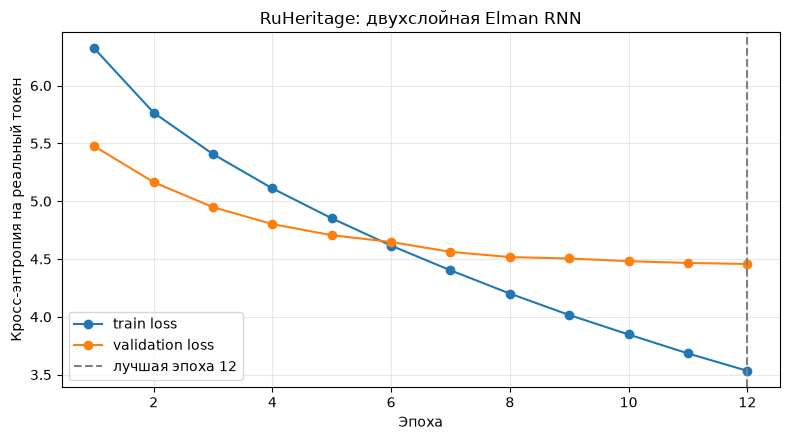

Лучшая эпоха: 12; validation CE=4.457040; PPL=86.231861
Запрос: 'однажды вечером'
               <unk>: 0.183049
                   и: 0.132371
              первая: 0.112503
                   я: 0.083085
                   о: 0.061969
Запрос: 'я не знаю'
                   в: 0.071018
               <unk>: 0.067227
                  ни: 0.043548
                  не: 0.043420
                 что: 0.039196
Запрос: 'он сказал'
               <unk>: 0.237824
                 что: 0.179157
                  по: 0.041460
                   в: 0.038293
                  из: 0.034900
Запрос: 'михаил ломоносов полидор'
             идиллия: 0.193393
           сочинений: 0.039253
          литература: 0.018271
                   и: 0.017156
              данные: 0.017067
Генерация: {"prompt": "однажды вечером", "new_tokens": ["<unk>", "<unk>", "<unk>", "<unk>", "<unk>", "<unk>", "<unk>", "<unk>", "<unk>", "<unk>", "<unk>", "<unk>", "<unk>", "<unk>", "<unk>", "<unk>"], "text": "однажды вечер

In [7]:
model.eval()
final_val_loss=run_epoch(val_loader,False)
perplexity=math.exp(final_val_loss)
assert math.isfinite(perplexity) and perplexity>0
assert abs(final_val_loss-best_val_loss)<1e-6
assert history['loss'][-1]<history['loss'][0]

epochs=np.arange(1,len(history['loss'])+1)
plt.figure(figsize=(8,4.5))
plt.plot(epochs,history['loss'],'o-',label='train loss')
plt.plot(epochs,history['val_loss'],'o-',label='validation loss')
plt.axvline(best_epoch,color='gray',linestyle='--',label=f'лучшая эпоха {best_epoch}')
plt.xlabel('Эпоха');plt.ylabel('Кросс-энтропия на реальный токен')
plt.title('RuHeritage: двухслойная Elman RNN');plt.grid(alpha=.3);plt.legend();plt.tight_layout()
plt.savefig(ARTIFACT_DIR/'learning_curve.png',dpi=140);plt.show()

def prompt_to_ids(prompt):
    return [BOS_IDX]+[stoi.get(word,UNK_IDX) for word in normalize_and_tokenize(prompt,MAX_SEQUENCE_LENGTH-1)]

@torch.no_grad()
def top_k_next_words(prompt,k=5):
    model.eval()
    ids=torch.tensor([prompt_to_ids(prompt)],dtype=torch.long,device=DEVICE)
    probabilities=torch.softmax(model(ids)[0,-1],dim=-1)
    assert torch.isclose(probabilities.sum(),torch.tensor(1.,device=DEVICE),atol=1e-6)
    values,indices=probabilities.topk(min(k,VOCAB_SIZE))
    # Никакие специальные токены не вырезаем и не перенормируем: показываем честный top-k.
    return [(itos[index],float(prob)) for index,prob in zip(indices.tolist(),values.tolist())]

@torch.no_grad()
def greedy_generate(prompt,max_new_tokens=16):
    model.eval();ids=prompt_to_ids(prompt);new_ids=[];stop_reason='limit'
    for _ in range(max_new_tokens):
        tensor=torch.tensor([ids],dtype=torch.long,device=DEVICE)
        next_id=int(model(tensor)[0,-1].argmax())
        new_ids.append(next_id)
        if next_id==EOS_IDX:stop_reason='eos';break
        ids.append(next_id)
    return {'prompt':prompt,'new_tokens':[itos[i] for i in new_ids],
            'text':' '.join([itos[i] for i in ids if i!=BOS_IDX]),'stop_reason':stop_reason}

prompts=['однажды вечером','я не знаю','он сказал', ' '.join(train_documents[0][:3])]
predictions={prompt:top_k_next_words(prompt) for prompt in prompts}
generations=[greedy_generate(prompt) for prompt in prompts[:3]]
print(f'Лучшая эпоха: {best_epoch}; validation CE={final_val_loss:.6f}; PPL={perplexity:.6f}')
for prompt,prediction in predictions.items():
    print('Запрос:',repr(prompt))
    for token,probability in prediction: print(f'  {token:>18}: {probability:.6f}')
for generation in generations:print('Генерация:',json.dumps(generation,ensure_ascii=False))
summary={'config':config,'data':data_stats,'parameters':parameter_count,
    'initial_val_loss':initial_val_loss,'best_epoch':best_epoch,'epochs':len(epochs),
    'val_loss':final_val_loss,'perplexity':perplexity,'history':history,
    'top_k':predictions,'generations':generations,'seconds':time.perf_counter()-experiment_start,
    'token_examples':[d[:16] for d in train_documents[:3]],
    'pair_example':{'tokens':example_tokens,'input':[itos[i] for i in x.tolist()],'target':[itos[i] for i in y.tolist()]},
    'shapes':{'input':list(sample_input_ids.shape),'embedding':list(diagnostic_embeddings.shape),
              'hidden':list(diagnostic_hidden.shape),'logits':list(diagnostic_logits.shape)}}
(ARTIFACT_DIR/'summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2))
print('Метрики, словарь, график и лучшие веса сохранены в',ARTIFACT_DIR)


## Этап 8. Самопроверка перед сдачей

- Использован RuHeritage-Corpus, его поле «text», каталог данных
  «data» и закреплённая ревизия.
- Словарь построен только по обучающей части; индексы PAD, UNK, BOS,
  EOS равны 0, 1, 2, 3.
- «input_ids» и «target_ids» имеют форму $(B,T)$, $T\leq32$.
- Эмбеддинги и скрытые состояния имеют форму $(B,T,128)$; логиты —
  $(B,T,V)$.
- PAD исключён из кросс-энтропии, а не заменён на обычную цель.
- Потери и перплексия конечны; сохранена лучшая валидационная модель.
- В коде нет TensorFlow, Keras и готового «nn.RNN».

## Итог выполненного эксперимента

Прочитаны 1200 пригодных записей, train/val=1000/200; фрагменты=5792/1170; V=6004; параметров=1608820.
Обучение завершено после 12 эпох по заданному пределу, лучшая эпоха 12. Восстановленные веса дали validation loss=4.457040, PPL=86.231861. Метрика снизилась относительно начальной CE=8.778181, но связная генерация не достигнута: argmax преимущественно выбирает UNK.

Доля UNK в валидации — 28.7673%. Между частями обнаружено 47 уникальных совпадающих нормализованных префиксов, поэтому разбиение по записям не обеспечивает полной независимости контента. В словарь валидационные частоты не добавлялись; это отдельное от повторов свойство предобработки.

Для «он сказал» вероятность «что» равна 0.179157, но UNK имеет большую вероятность. Для учебного префикса «михаил ломоносов полидор» лидирует «идиллия», присутствующая в обучающем документе. Эти наблюдения показывают усвоение локальных статистик и ограничения переноса на новый связный текст.

Полный отчёт находится в `Отчёт RNN.md`, персональный конспект — в `Краткий конспект.md`. Лучшие веса, словарь и метрики сохранены в `artifacts/assignment/`.

# Ответы на контрольные вопросы

## Вопросы лабораторной

1. **Почему индекс токена нельзя подавать как обычное вещественное число?** Индекс — произвольный идентификатор. Разность между индексами не измеряет смысловую близость: перестановка словаря не должна менять смысл слов. Embedding превращает идентификатор в обучаемый вектор признаков.

2. **Почему словарь строится только по обучающим документам?** Иначе состав словаря и частоты будут зависеть от отложенной выборки. Это утечка информации в предобработку. Незнакомые слова валидации отображаются в UNK; словарь не расширяется.

3. **Какие пары получаются из (BOS, a, b, EOS)?** Вход — (BOS, a, b), цель — (a, b, EOS). На каждой позиции нужно предсказать следующий токен, а не повторить текущий.

4. **Чем PAD отличается от UNK?** PAD означает отсутствующую позицию, добавленную для выравнивания длины; UNK — настоящее слово, которого нет в ограниченном словаре. PAD исключается из потери, UNK остаётся целью. Если исключить UNK, модель перестанет отвечать за часть реальных слов.

5. **Какова форма логитов?** (B,T,V): для каждого из B фрагментов, на каждой из T позиций выдаётся оценка каждого из V токенов. Для CrossEntropyLoss формы преобразуются в (B·T,V) и (B·T).

6. **Почему целевые индексы подходят для CrossEntropyLoss?** На каждой позиции решается задача классификации следующего токена по V классам. Цель — индекс правильного класса-токена; наличие или отсутствие метки всего документа не имеет значения.

7. **Что произойдёт при включении PAD в потерю?** Модель будет вознаграждаться за предсказание технических нулей. Оценка станет зависеть от количества дополнения и состава пакета, а обучение потратит часть усилий на фиктивную задачу. Правильный знаменатель — число целей, не равных PAD.

8. **Что обновляет optimizer.step()?** Таблицу эмбеддингов, входные и рекуррентные матрицы и смещения обоих слоёв, выходную матрицу и её смещение. Индексы, цели, маски и размеры тензоров не обновляются. Скрытые состояния — промежуточные вычисления, а не отдельные параметры. PAD-строка эмбеддинга изначально нулевая и не получает градиент; при используемом AdamW остаётся нулевой, что проверено.

9. **Почему PPL сравнивается при одинаковых словаре и токенизации?** Кросс-энтропия определяется на токен, а токенизация и словарь определяют сами события, множество классов и долю UNK. При разных словарях PPL относятся к разным задачам. Поэтому результаты Gazeta и RuHeritage нельзя ранжировать как честное сравнение качества двух моделей.

10. **Что означают оси (B,T,128)?** B — независимые последовательности мини-пакета, T — позиции внутри каждой последовательности, 128 — координаты вектора признаков на позиции. Два рекуррентных слоя не означают отдельную ось размера 2 в выходе: наружу возвращается последовательность состояний верхнего слоя.

## Дополнительные вопросы из теоретического пособия

1. **Что хранит скрытое состояние и зачем нулевое начальное состояние?** hₜ — обучаемое сжатое представление прочитанного префикса. Нулевое h₀ задаёт единое начало без накопленного контекста. В этой работе h₀ сбрасывается для каждого окна: модель не переносит память между окнами.

2. **Почему веса в пакетной формуле транспонируются?** Параметр W хранится как (выходные признаки, входные признаки), а пакет X — как (объекты, входные признаки). Поэтому XWᵀ имеет нужную форму (объекты, выходные признаки); это та же операция, что Wx для одного вектора-столбца.

3. **Зачем ModuleList?** Он регистрирует вложенные модули: их параметры видны в model.parameters(), state_dict() и при переносе устройства. Обычный список Python сам по себе такой регистрации не обеспечивает.

4. **Почему перед CrossEntropyLoss не нужен softmax?** Функция принимает логиты и сама вычисляет устойчивый log-softmax с отрицательным логарифмом вероятности правильного класса. Если заранее передать вероятности, функция ошибочно воспримет их как логиты. Softmax отдельно нужен при интерпретации прогноза.

5. **Чем отличаются Dataset и DataLoader?** Dataset возвращает один пример — пару вход/цель. DataLoader выбирает и при необходимости перемешивает примеры, собирает мини-пакеты и вызывает collate_fn. Последняя дополняет короткие последовательности справа.

6. **Почему трудно учить далёкие зависимости?** При обратном распространении через время многократно перемножаются матрицы и производные tanh. Градиенты могут затухать или расти, а фиксированное состояние ограничивает память. Clipping ограничивает взрыв градиента, но не устраняет затухание и не увеличивает длину контекста.
